# Customer Churn: Exploratory Data Analysis and Preprocessing

Research Report: A Comparative Machine Learning Approach to Predicting Customer Churn in the Telecommunications Industry

Student: Saihil Gurupersad, ST10294145

This notebook looks at the data and cleans it up before it is used for modelling later. The dataset used is the extended IBM Telco Customer Churn dataset (IBM, 2020). It contains 7043 customer records and 33 features, including demographics, account details, the services each customer uses, and whether or not they churned.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

In [2]:
df = pd.read_excel("Telco_customer_churn.xlsx")
print("Shape:", df.shape)
df.head()

Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
print(df.shape)
df.info()

(7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 

Instead of being saved as a number, Total Charges is stored as text. This makes sense because, according to Sana et al. (2022), this feature in the Telco dataset contains missing values that are shown as blank strings rather than real nulls, which must be found and handled before the column can be used numerically. The preprocessing steps listed below address this.

Churn Reason only has 1869 non-null values out of 7043. This is not a data quality issue, only customers who churned have a reason recorded, and 1869 is close to the 26.5 percent churn rate mentioned in the proposal. This column will be dropped later regardless, since it is a leakage risk.

## Understanding the Dataset

Before exploring or cleaning the data, every column is defined here in plain terms. This ensures each pattern found later can be explained using what the feature actually represents, not just the numbers on their own.

The dataset groups naturally into a few categories, matching how it is described in the proposal (Section 3.2):

Identifier: CustomerID, a unique code for each customer, not useful for prediction.

Demographic features: Gender, Senior Citizen (whether the customer is 65 or older), Partner (has a spouse or partner), Dependents (has children or other dependents living with them).

Geographic features: Country, State, City, Zip Code, Latitude, Longitude, Lat Long. All customers in this dataset are based in the United States, these are synthetic locations and carry no real predictive value.

Account features: Tenure Months (how many months the customer has been with the company), Contract (month to month, one year, or two year), Paperless Billing (Yes or No), Payment Method (how the customer pays their bill), Monthly Charges (amount billed per month), Total Charges (total amount billed over the customer's whole tenure).

Service features: Phone Service, Multiple Lines, Internet Service (DSL, Fiber optic, or No internet), Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies. These describe which services and add ons each customer subscribes to.

Churn related fields: Churn Label (Yes or No), Churn Value (0 or 1, the numeric target), Churn Score (a pre built risk score), CLTV (Customer Lifetime Value), Churn Reason (why the customer left, only filled in for customers who churned).

Churn Score, CLTV, and Churn Reason are excluded later during preprocessing, since they either encode the outcome directly or would not be available before a customer actually leaves.

# Data Quality Check


## Checking for duplicates

In [4]:
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["CustomerID"].duplicated().sum()

print("Fully duplicated rows:", duplicate_rows)
print("Duplicate CustomerID values:", duplicate_ids)

Fully duplicated rows: 0
Duplicate CustomerID values: 0


The reason no duplicates were found, was because this dataset is synthetic.

## Checking for Missing Values

Before any cleaning happens, the dataset is checked for missing values, including values that may be hidden as blank strings rather than proper nulls.

In [5]:
blank_count = (df["Total Charges"].astype(str).str.strip() == '').sum()
print("Blank values in Total Charges:", blank_count)

Blank values in Total Charges: 11


In [6]:
df[df["Total Charges"].astype(str).str.strip() == ""][["Tenure Months", "Monthly Charges", "Total Charges"]]

,Tenure Months,Monthly Charges,Total Charges
2234,0,52.55,
2438,0,20.25,
2568,0,80.85,
2667,0,25.75,
2856,0,56.05,
4331,0,19.85,
4687,0,25.35,
5104,0,20.00,
5719,0,19.70,
6772,0,73.35,


These 11 blank values all correspond to customers with a Tenure Months of 0, meaning they had only just joined and had not yet completed a full billing cycle. This explains why Total Charges is missing for these customers specifically, it reflects a genuine absence of billing history rather than a data entry error, and supports the choice to fill these values through imputation rather than treating them as a data quality problem requiring removal.

# Exploratory Data Analysis Plan

This section outlines what will be explored before preprocessing begins. The following areas are covered, in order:

- Section 1: Target Variable and Class Imbalance
- Section 2: Numerical Feature Distributions
- Section 3: Numerical Features Against Churn
- Section 4: Categorical Features Against Churn
- Section 5: Correlation Between Numerical Features
- Section 6: Demographic Features Against Churn
- Section 7: Overview of Remaining Service Features

# Section 1: Target Variable and Class Imbalance

This section checks the balance between customers who churned and customers who did not. Class imbalance affects how the models are trained and evaluated later, so it needs to be confirmed early (Suguna et al., 2025).

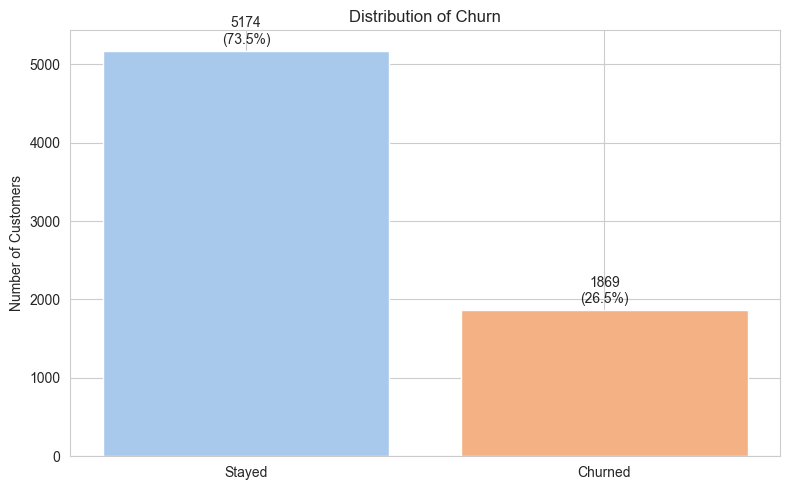

In [7]:
churn_counts = df["Churn Value"].value_counts().sort_index()
churn_pct = df["Churn Value"].value_counts(normalize=True).sort_index() * 100
labels = ["Stayed", "Churned"]

plt.figure()
bars = plt.bar(labels, churn_counts.values, color=['#a8c8ec', '#f4b183'])

for bar, count, pct in zip(bars, churn_counts.values, churn_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
              f"{count}\n({pct:.1f}%)", ha='center', va='bottom')

plt.title("Distribution of Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("Diagrams/churn_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

## Interpretation:
The information includes 1869 customers that churned (26.5%) and 5174 customers who stayed (73.5%). This supports the proposal's claim of a class imbalance. Accuracy alone would not provide a realistic picture of the model's success later on since a model that forecasted every client as "stayed" would already attain about 73.5 percent accuracy without accurately detecting a single churner (Geiler et al., 2022). For this reason, the main assessment measures in this work are the F1 score and AUC ROC.

Figure 1: Shows the distribution of consumers who have churned against those who have not, along with the number and percentage of each category.

# Section 2: Numerical Feature Distributions

Tenure Months, Monthly Charges, and Total Charges are the three numerical features in the dataset whose shapes are examined in this section. Because Logistic Regression is sensitive to variations in feature scale, examining these distributions aids in determining whether scaling is required prior to modelling (Sana et al., 2022).

Total Charges is still stored as text at this point, so it is converted to a number just for this plot. The actual fix for its missing values happens later in preprocessing.

A histogram with a smoothed density line (KDE) is used here, since it is the standard way to show the shape of a single numerical feature, whether it is spread out or clustered, symmetrical or skewed, single peaked or multi peaked. This shape is not visible from summary statistics alone, so the plot and the descriptive statistics table below are used together.

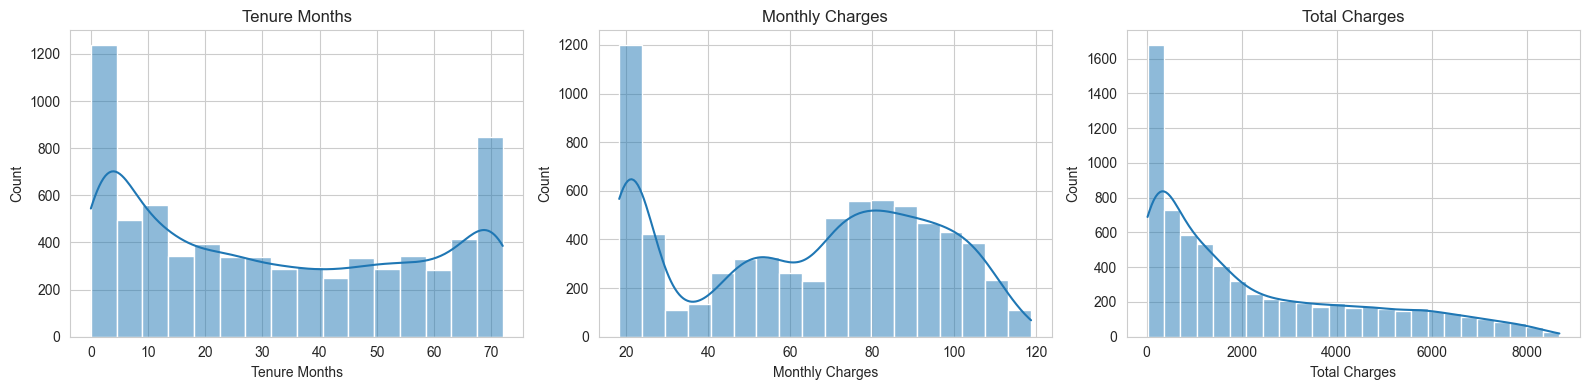

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Tenure Months"], kde=True, ax=axes[0])
axes[0].set_title("Tenure Months")

sns.histplot(df["Monthly Charges"], kde=True, ax=axes[1])
axes[1].set_title("Monthly Charges")

sns.histplot(pd.to_numeric(df["Total Charges"], errors='coerce'), kde=True, ax=axes[2])
axes[2].set_title("Total Charges")

plt.tight_layout()
plt.savefig("Diagrams/numerical_distributions.png", dpi=150, bbox_inches='tight')
plt.show()

A descriptive statistics table is included here alongside the histograms, since a chart alone shows the general shape of a distribution but does not give exact numbers. The table below gives the count, mean, standard deviation, minimum, maximum, and quartile values for each of the three numerical features, which is used to support the interpretation that follows.

In [9]:
df[["Tenure Months", "Monthly Charges", "Total Charges"]].apply(pd.to_numeric, errors='coerce').describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


## Interpretation:
The table above gives the mean, standard deviation, minimum, maximum, and quartile values for the three numerical features, alongside the distribution shapes shown in the histograms. Total Charges shows a count of 7032, 11 fewer than the other two features, which matches the 11 missing values already identified during the data quality check.

Tenure Months has a mean of 32.4 months and a median of 29 months, fairly close together, but a high standard deviation of 24.6 relative to the mean, indicating customers are widely spread across the full range rather than clustered near the average. This is consistent with the bimodal shape seen in the histogram. Monthly Charges shows a similar pattern, a standard deviation of 30.1 against a mean of 64.8, again reflecting the two visible peaks rather than a single typical value.

Tenure Months and Monthly Charges both show a bimodal pattern, with two visible peaks rather than one. This may suggest that the customer base includes more than one type of customer, for example, customers with minimal service usage and customers with more extensive, higher cost service plans. This is a pattern worth investigating further, rather than a confirmed segmentation, since a histogram shape alone does not prove that distinct customer groups exist, that would require further analysis such as clustering.

Total Charges shows a mean of 2283.30 but a median of only 1397.48, the mean being pulled higher than the median is a typical sign of right skew, matching what the histogram shows. This is expected, since Total Charges accumulates as tenure increases, so most customers who have not been with the company as long naturally fall toward the lower end, while a smaller number of long tenure customers pull the distribution's tail out to the right. This supports the need for feature scaling before modelling, particularly for Logistic Regression, since large differences in feature scale can otherwise distort how the model weighs each feature (Sana et al., 2022).

Figure 2: Distribution of Tenure Months, Monthly Charges, and Total Charges, alongside descriptive statistics for each. Tenure Months and Monthly Charges show a bimodal shape, while Total Charges is heavily right skewed with its mean pulled above its median.

# Section 3: Numerical Features Against Churn

A boxplot is used here to compare Tenure Months, Monthly Charges, and Total Charges between churned and non-churned customers. Unlike a histogram, which shows the shape of one group on its own, a boxplot makes it easy to compare the median and spread of two groups side by side, which is useful here since the goal is to see whether these three features differ between customers who churned and customers who stayed.

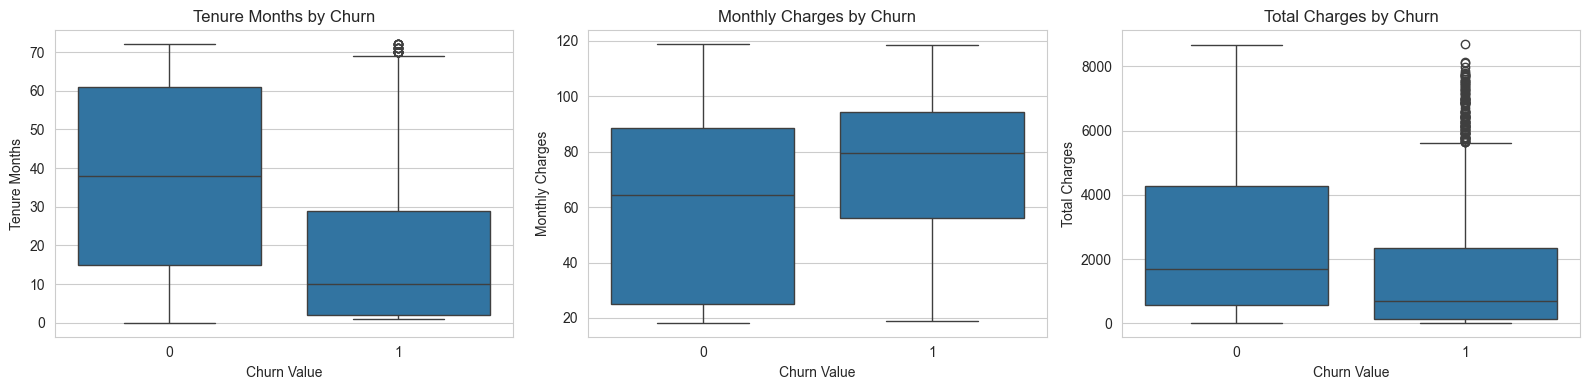

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="Churn Value", y="Tenure Months", ax=axes[0])
axes[0].set_title("Tenure Months by Churn")

sns.boxplot(data=df, x="Churn Value", y="Monthly Charges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")

plot_df = df.copy()
plot_df["Total Charges"] = pd.to_numeric(plot_df["Total Charges"], errors='coerce')
sns.boxplot(data=plot_df, x="Churn Value", y="Total Charges", ax=axes[2])
axes[2].set_title("Total Charges by Churn")

plt.tight_layout()
plt.savefig("Diagrams/numerical_vs_churn.png", dpi=150, bbox_inches='tight')
plt.show()

## Interpretation:
A pattern appears across all three charts. Churned customers show a lower median Tenure Months, and the smaller box size suggests this tends to happen earlier in the customer relationship rather than spread evenly over time, though there is still a fair amount of variation within the group, not every churned customer fits this pattern. Churned customers also show a higher median Monthly Charges, suggesting churn is more common among a specific range of higher spending customers rather than occurring evenly across all spending levels.

This appears to conflict with the Total Charges chart, which shows a lower median for churned customers. However, taking the first two findings together, this makes sense. Churned customers do not stay long enough to accumulate as high a Total Charges as customers who remain with the company longer, even though their monthly rate tends to be higher.

A small number of high value outliers appear above the churned group's box in the Total Charges chart. These were not removed, since they likely represent valid, longer standing customers who eventually churned, rather than data errors. Values that fall beyond the whiskers of a boxplot are not automatically errors, and removing them without justification would discard legitimate information rather than correct a mistake.

Figure 3: Tenure Months, Monthly Charges, and Total Charges compared between churned and non-churned customers. Churned customers show lower tenure, higher monthly charges, and lower total charges, suggesting an association between early churn and higher paying customers.

# Section 4: Categorical Features Against Churn

This section checks whether categorical features like contract type and payment method relate to churn. Contract type and tenure were repeatedly identified as strong churn predictors in the literature (Sinaga and Widianto, 2023; Peng and Peng, 2022), so this is a chance to see if that pattern shows up in this dataset too.

For readability, a temporary Churn Status column is created here, labelling customers as Stayed or Churned instead of 0 or 1. This is only used for plotting, the original Churn Value column is kept as is for modelling later.

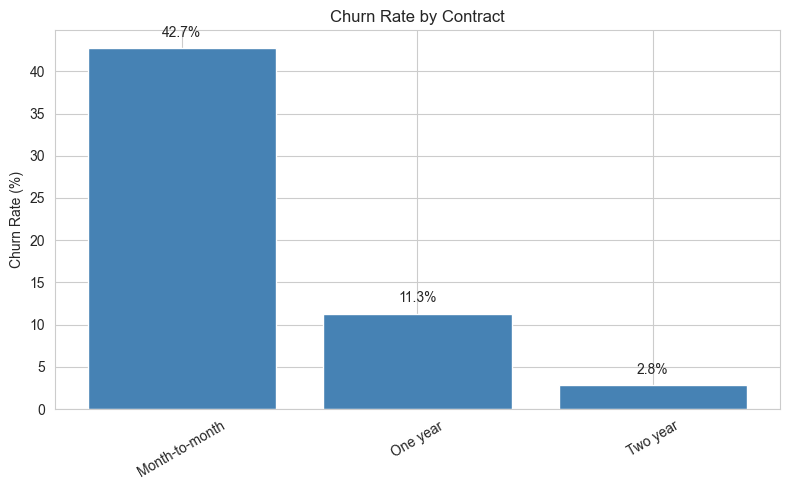

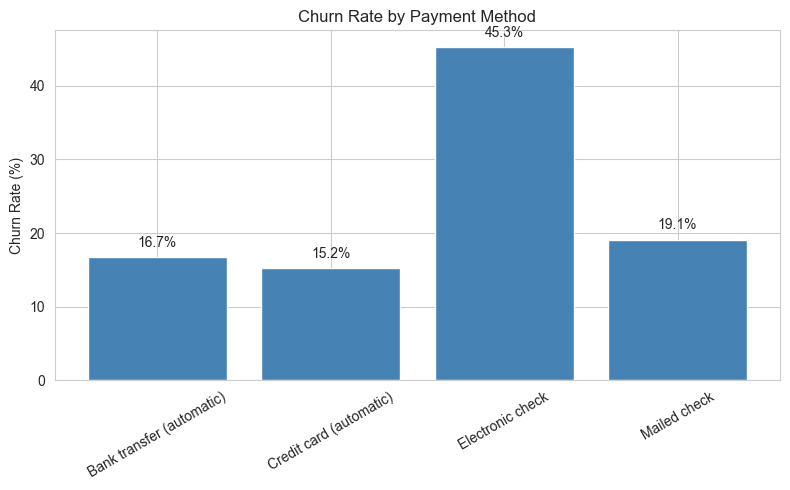

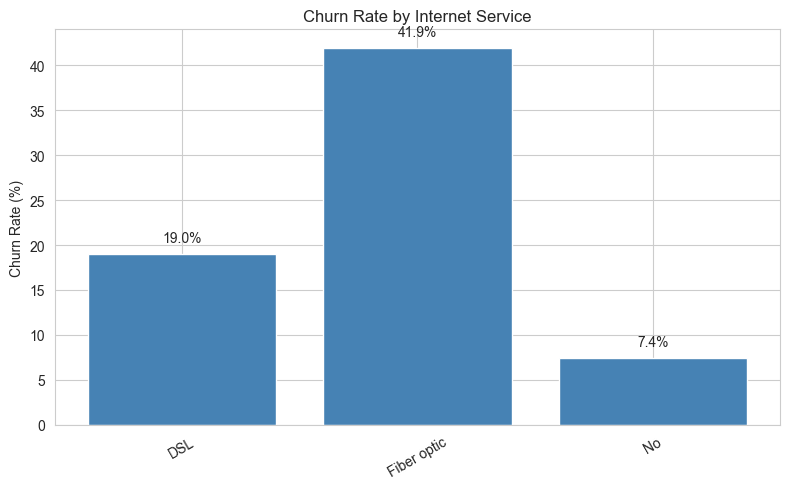

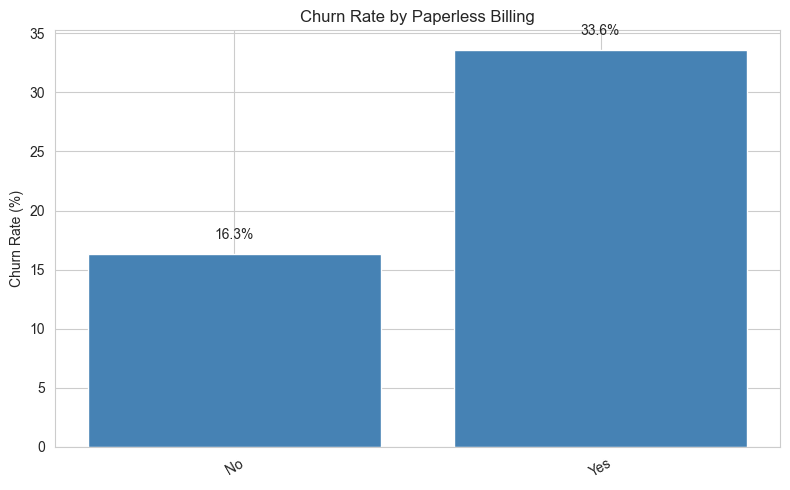

In [11]:
categorical_checks = ["Contract", "Payment Method", "Internet Service", "Paperless Billing"]

for col in categorical_checks:
    rate = df.groupby(col)["Churn Value"].mean() * 100
    plt.figure()
    bars = plt.bar(rate.index.astype(str), rate.values, color='steelblue')
    for bar, pct in zip(bars, rate.values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                  f"{pct:.1f}%", ha='center', va='bottom')
    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig(f"Diagrams/churn_rate_by_{col.replace(' ', '_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

Instead of depending solely on a visual comparison of bar heights, a chi-square test of independence and Cramér's V are used to determine whether and how strong an association with churn exists because Contract, Payment Method, Internet Service, and Paperless Billing are all categorical. Cramér's V is a number between 0 and 1, where values around 0.1 are regarded as weak, 0.3 as moderate, and 0.5 or above as strong.

In [12]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(col):
    contingency = pd.crosstab(df[col], df["Churn Value"])
    chi2, p, dof, expected = chi2_contingency(contingency)
    n = contingency.sum().sum()
    min_dim = min(contingency.shape) - 1
    v = np.sqrt(chi2 / (n * min_dim))
    return chi2, p, v

for col in categorical_checks:
    chi2, p, v = cramers_v(col)
    print(f"{col}: chi2 = {chi2:.2f}, p = {p:.4f}, Cramér's V = {v:.3f}")

Contract: chi2 = 1184.60, p = 0.0000, Cramér's V = 0.410
Payment Method: chi2 = 648.14, p = 0.0000, Cramér's V = 0.303
Internet Service: chi2 = 732.31, p = 0.0000, Cramér's V = 0.322
Paperless Billing: chi2 = 258.28, p = 0.0000, Cramér's V = 0.191


## Interpretation:
All four features show a statistically significant association with churn (p < 0.001). Contract shows the strongest association (Cramér's V = 0.410), followed by Internet Service (V = 0.322), Payment Method (V = 0.303), and Paperless Billing, which shows the weakest association of the four (V = 0.191).

The churn rate for customers on month-to-month contracts is 42.7%, whereas it is 11.3% for one-year contracts and 2.8% for two-year contracts. This trend is in line with earlier studies by (Sinaga & Widianto, 2023) and (Peng & Peng, 2022), who found that contract type was a powerful churn predictor. One reason may be that, in contrast to clients under a fixed-term contract, month-to-month customers are not penalised for quitting; however, this EDA can only demonstrate the correlation, not verify the underlying cause.

Electronic check shows a churn rate of 45.3 percent, notably higher than bank transfer (16.7 percent), credit card (15.2 percent), or mailed check (19.1 percent). Fiber optic shows a churn rate of 41.9 percent, compared to 19.0 percent for DSL and 7.4 percent for customers with no internet service at all. Paperless billing shows a smaller difference, 33.6 percent for customers with it enabled compared to 16.3 percent without, the weakest of the four associations, consistent with its lower Cramér's V value.

These findings explain the relationships that were found between each attribute and churn. They do not prove that any of these elements are the primary cause of a customer's departure; the pattern may also be influenced by other unmeasured factors.

Figure 4: Illustrates the churn rate by Contract, Payment Method, Internet Service, and Paperless Billing. The chi-square and Cramér's V findings reveal that Contract has the strongest connection, followed by Internet Service, Payment Method, and Paperless Billing.

# Section 5: Correlation Between Numerical Features

This section checks how strongly Tenure Months, Monthly Charges, and Total Charges relate to each other. This is mainly a quick check before preprocessing, high correlation between features can sometimes cause issues for certain models, so it is worth confirming here.

A heatmap is used here since it shows the correlation between every pair of numerical features at once, using color to make strong and weak relationships easy to spot at a glance. This would be harder to read from a plain table once there are more than a few features to compare.

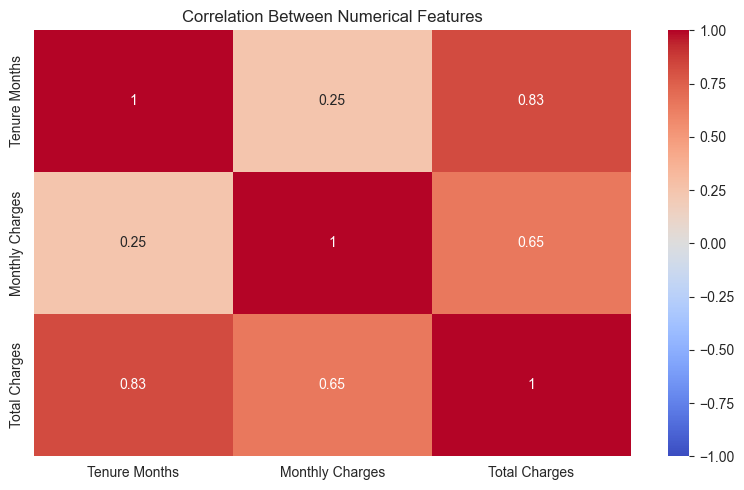

In [13]:
plot_df = df.copy()
plot_df["Total Charges"] = pd.to_numeric(plot_df["Total Charges"], errors='coerce')

numerical_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
corr_matrix = plot_df[numerical_cols].corr()

plt.figure()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.savefig("Diagrams/correlation_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

VIF measures whether a feature can be largely predicted using the other features in the dataset. If it can, that feature is carrying mostly redundant information, which is exactly the concern with Tenure Months and Total Charges being correlated. Concretely, for each feature, it tries to predict that feature using the other two, then converts how well that prediction worked into a single number.

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = plot_df[numerical_cols].dropna().copy()
vif_df["const"] = 1

vif_results = pd.DataFrame()
vif_results["Feature"] = numerical_cols
vif_results["VIF"] = [variance_inflation_factor(vif_df.values, i) for i in range(len(numerical_cols))]
vif_results

,Feature,VIF
0,Tenure Months,5.844646
1,Monthly Charges,3.225293
2,Total Charges,9.526697


## Interpretation:

The VIF results show Monthly Charges at 3.23, well within the acceptable range. Tenure Months (5.84) and Total Charges (9.53) both fall into the range generally considered worth watching, with Total Charges close to the commonly used threshold of 10. This is consistent with the 0.83 correlation observed between Tenure Months and Total Charges, and confirms that some multicollinearity is present between these two features.

None of the three values exceed 10, so this does not require removing a feature outright. However, since Total Charges shows the highest VIF and is closely tied to Tenure Months by construction, Logistic Regression's coefficients for these two features should be interpreted with some caution later, since multicollinearity can make individual coefficient estimates less stable, even where overall model performance is not necessarily affected. Random Forest and LightGBM are not affected by this in the same way, since they do not rely on estimating individual linear coefficients. All three numerical features are retained for modelling, consistent with the approach outlined in the proposal.

Figure 5: Correlation between Tenure Months, Monthly Charges, and Total Charges, alongside Variance Inflation Factor (VIF) results. Total Charges and Tenure Months show a VIF close to the commonly used threshold of 10, consistent with their strong correlation, while Monthly Charges shows no meaningful multicollinearity concern.

# Section 6: Demographic Features Against Churn

This section examines whether churn varies according to senior citizen status and gender. This is included because, rather than supposing that the model acts uniformly for all demographic groups, the proposal's ethical considerations demand that model performance be examined across demographic groupings.

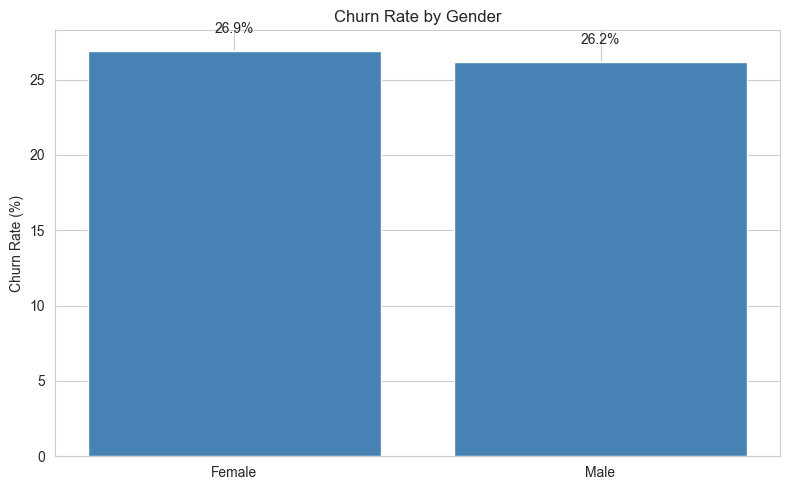

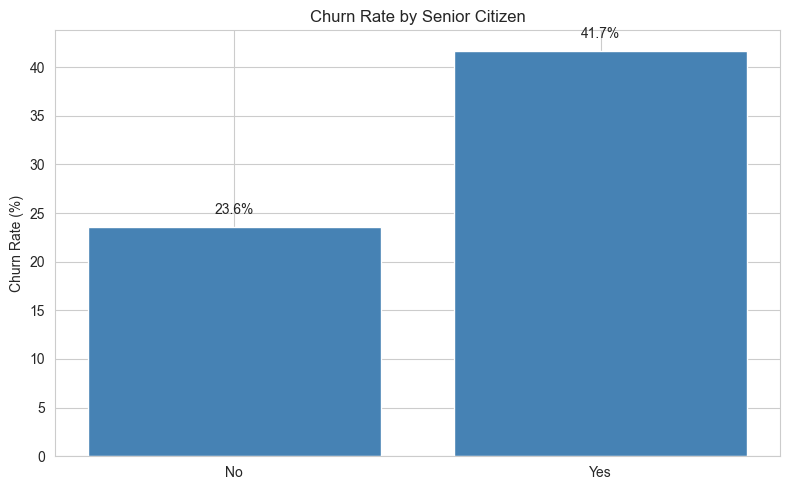

In [15]:
demographic_checks = ["Gender", "Senior Citizen"]

for col in demographic_checks:
    rate = df.groupby(col)["Churn Value"].mean() * 100
    plt.figure()
    bars = plt.bar(rate.index.astype(str), rate.values, color='steelblue')
    for bar, pct in zip(bars, rate.values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                  f"{pct:.1f}%", ha='center', va='bottom')
    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate (%)")
    plt.tight_layout()
    plt.savefig(f"Diagrams/churn_rate_by_{col.replace(' ', '_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

In [16]:
demographic_checks = ["Gender", "Senior Citizen"]

for col in demographic_checks:
    chi2, p, v = cramers_v(col)
    print(f"{col}: chi2 = {chi2:.2f}, p = {p:.4f}, Cramér's V = {v:.3f}")

Gender: chi2 = 0.48, p = 0.4866, Cramér's V = 0.008
Senior Citizen: chi2 = 159.43, p = 0.0000, Cramér's V = 0.150


In [17]:
pd.crosstab(df["Senior Citizen"], df["Payment Method"], normalize='index') * 100

Payment Method,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Senior Citizen,,,,
No,22.216573,22.047111,30.011862,25.724453
Yes,20.402802,19.352014,52.014011,8.231173


## Interpretation:

At first glance, one may think that this discrepancy is related to seniors' lower propensity to use electronic payment methods. The data, however, reveals the opposite tendency. Compared to non-seniors, seniors use electronic checks more frequently (52.0%) and use all other payment methods less frequently (30.0%).

The payment method with the highest recorded churn rate was electronic checks, as was already mentioned in the preceding section. Although this correlation does not prove that one causes the other, there may be other unmeasured factors at play. However, the overlap between Senior Citizen status and Electronic Check usage indicates that these two trends may be connected. In order to determine the relative impact of each characteristic, it could be worthwhile to revisit this at the modelling stage of SHAP analysis.

This is broadly consistent with (Zhang et al. 2022), who found that churn factors can vary across different customer segments rather than applying uniformly across the whole customer base.

Figure 6: Churn rate by gender and senior citizen, along with the distribution of payment methods across senior citizen groupings. There is no statistically significant correlation between gender and churn. Senior Citizens have a statistically significant but somewhat smaller connection, which may be related to senior clients using electronic checks more frequently.

# Section 7: Overview of Remaining Service Features

The remaining service-related columns that were not addressed in previous sections are briefly summarised in this section. Based on what was learned in Section 6, churn rate is computed directly for each category rather than comparing raw counts because some of the categories within these columns have extremely varied group sizes.

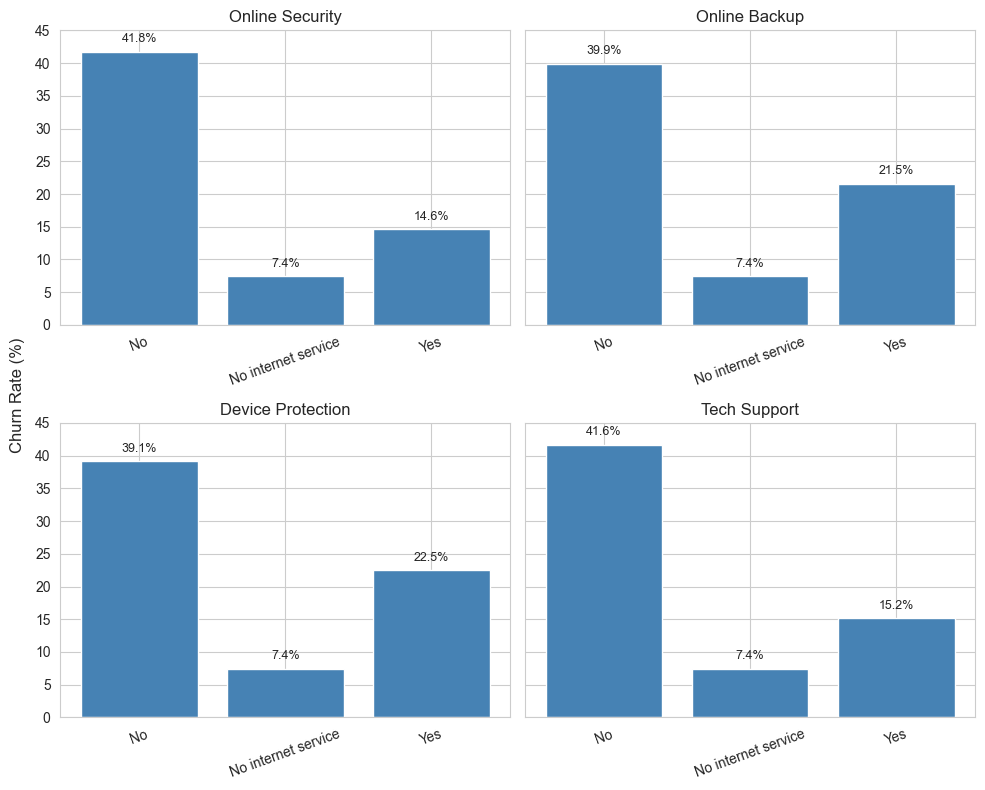

In [18]:
protection_support_cols = ["Online Security", "Online Backup", "Device Protection", "Tech Support"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
axes = axes.flatten()

for ax, col in zip(axes, protection_support_cols):
    rate = df.groupby(col)["Churn Value"].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color='steelblue')
    for bar, pct in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f"{pct:.1f}%", ha='center', va='bottom', fontsize=9)
    ax.set_title(col)
    ax.set_ylim(0, 45)
    ax.tick_params(axis='x', rotation=20)

fig.supylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("Diagrams/protection_support_features_churn_rate.png", dpi=150, bbox_inches='tight')
plt.show()

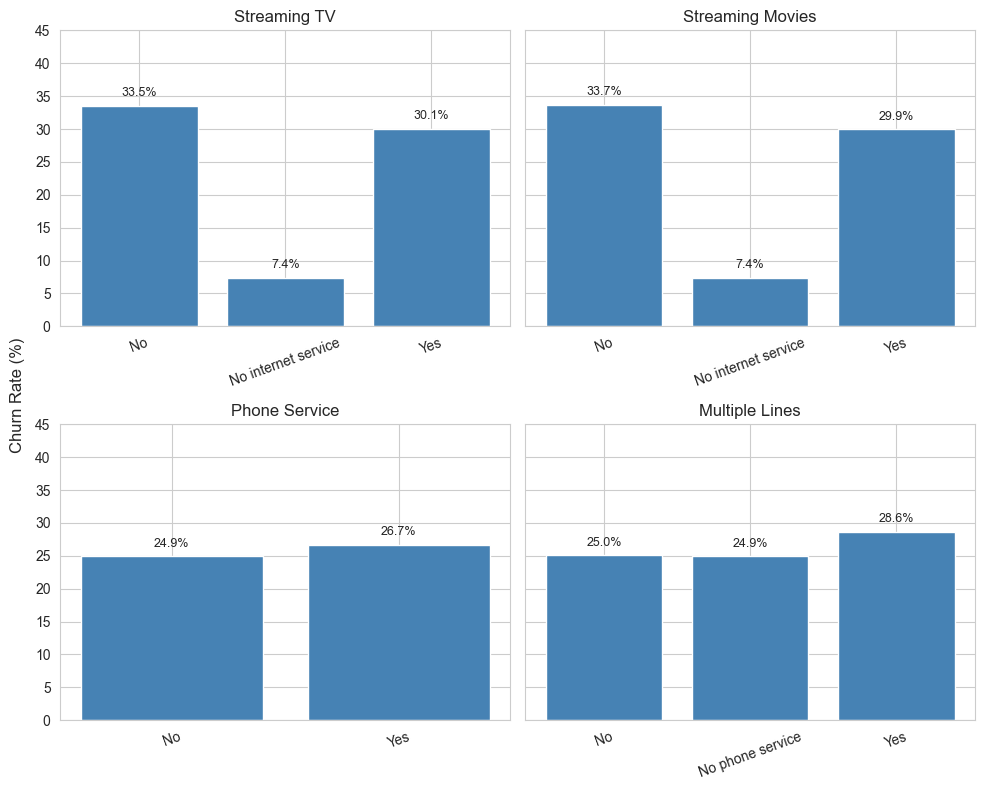

In [19]:
entertainment_basic_cols = ["Streaming TV", "Streaming Movies", "Phone Service", "Multiple Lines"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
axes = axes.flatten()

for ax, col in zip(axes, entertainment_basic_cols):
    rate = df.groupby(col)["Churn Value"].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color='steelblue')
    for bar, pct in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f"{pct:.1f}%", ha='center', va='bottom', fontsize=9)
    ax.set_title(col)
    ax.set_ylim(0, 45)
    ax.tick_params(axis='x', rotation=20)

fig.supylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("Diagrams/entertainment_basic_features_churn_rate.png", dpi=150, bbox_inches='tight')
plt.show()

In [20]:
remaining_service_cols = protection_support_cols + entertainment_basic_cols

for col in remaining_service_cols:
    chi2, p, v = cramers_v(col)
    print(f"{col}: chi2 = {chi2:.2f}, p = {p:.4f}, Cramér's V = {v:.3f}")

Online Security: chi2 = 850.00, p = 0.0000, Cramér's V = 0.347
Online Backup: chi2 = 601.81, p = 0.0000, Cramér's V = 0.292
Device Protection: chi2 = 558.42, p = 0.0000, Cramér's V = 0.282
Tech Support: chi2 = 828.20, p = 0.0000, Cramér's V = 0.343
Streaming TV: chi2 = 374.20, p = 0.0000, Cramér's V = 0.231
Streaming Movies: chi2 = 375.66, p = 0.0000, Cramér's V = 0.231
Phone Service: chi2 = 0.92, p = 0.3388, Cramér's V = 0.011
Multiple Lines: chi2 = 11.33, p = 0.0035, Cramér's V = 0.040


## Interpretation:

The chi-square test and Cramér's V were applied to all eight remaining service features, using the same approach as previous sections.

There is no statistically significant association between phone service and churn (p = 0.339). Multiple Lines shows a statistically significant association (p = 0.004), but the Cramér's V value is very low (0.040), so while the result passes the formal test, the actual difference in churn between groups is very small. This is a common outcome with large datasets, where even tiny differences can pass a significance test without representing a meaningful practical difference.

The other six features all show a statistically significant association with churn (p < 0.001). Online Security (V = 0.347) and Tech Support (V = 0.343) show the strongest associations of the eight, followed by Online Backup (V = 0.292) and Device Protection (V = 0.282). Streaming TV (V = 0.231) and Streaming Movies (V = 0.231) show a weaker, though still present, association.

Customers using the service have a reduced observed churn rate, ranging from around 15% (Online Security, Tech Support) to about 30% (Streaming TV, Streaming Movies), whereas customers without the service show a churn rate of about 33 to 42%. This is only an observed pattern. It does not prove that having these services makes a customer stay. Tenure or contract type may also play a role.

The "No internet service" category typically has the lowest churn rate (about 7.4%) among the six features. Since these customers have no internet access at all, this group should not be seen as customers who simply turned down an add on. They are a separate group of customers entirely, and the lower churn rate may reflect a different overall customer profile rather than the missing feature itself.

Figure 7: Churn rate for Online Security, Online Backup, Device Protection, and Tech Support. All four show a statistically significant association with churn, with Online Security and Tech Support showing the strongest associations among the eight features tested in this section.

Figure 8: Churn rate for Streaming TV, Streaming Movies, Phone Service, and Multiple Lines. Streaming TV and Streaming Movies show a weaker but statistically significant association with churn. Phone Service shows no significant association, and Multiple Lines shows a statistically significant association with a very small effect size.

# Preprocessing



The following steps clean and prepare the dataset for modelling, following the pipeline described in the Methodology section of the proposal. This involves dropping unnecessary or leakage prone columns, fixing missing values, and encoding categorical variables into a numeric form the models can use.

## Preprocessing Step 1: Drop Excluded Columns

Here, the columns mentioned in the proposal's Table 1 are eliminated. These are either features that would directly leak the result into the model (Churn Score, CLTV, Churn Reason), identifiers with little predictive value, or geographic fields with no true variance because the dataset is synthetic. Since Churn Value is already being utilised and Churn Label is merely a text form of it, it is likewise dropped here.

In [21]:
columns_to_drop = [
    "CustomerID", "Count", "Country", "State", "City", "Zip Code",
    "Lat Long", "Latitude", "Longitude",
    "Churn Score", "CLTV", "Churn Reason", "Churn Label"
]

df_clean = df.drop(columns=columns_to_drop)
print("Shape before:", df.shape)
print("Shape after dropping:", df_clean.shape)
df_clean.head()

Shape before: (7043, 33)
Shape after dropping: (7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1


## Preprocessing Step 2: Save the Dataset for Modelling

This notebook only drops the excluded columns. Fixing the missing Total Charges values and encoding the categorical columns now happens in churn_modeling.ipynb, after the data is split into training and test sets. Doing it there instead of here means the median used to fill in Total Charges, and the categories learned during encoding, are worked out only from the training data. This avoids data leakage, since none of the test set information leaks into how the training data gets processed (per supervisor feedback, point 10).

Because of this, the file saved here still has the 11 blank Total Charges values, and Total Charges and the categorical columns are still stored as text rather than numbers. These get handled in churn_modeling.ipynb.

In [22]:
df_clean.to_csv("cleaned_churn_data.csv", index=False)
print("Saved cleaned_churn_data.csv with shape:", df_clean.shape)

Saved cleaned_churn_data.csv with shape: (7043, 20)


# Reference List

Geiler, L., Affeldt, S. and Nadif, M., 2022. A survey on machine learning methods for churn prediction. International Journal of Data Science and Analytics, 14(3), pp.217–242. Available at: https://link.springer.com/article/10.1007/s41060-022-00312-5. Accessed on: 11/06/2026

IBM, 2020. Telco customer churn: IBM dataset. [Online] Available at: https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset. Accessed on: 11/06/2026

Peng, K. and Peng, Y., 2022. Research on telecom customer churn prediction based on GA-XGBoost and SHAP. Journal of Computer and Communications, 10(1), pp.107–120. Available at: https://www.scirp.org/journal/paperinformation?paperid=121175. Accessed on: 11/06/2026

Sana, J.K., Abedin, M.Z., Rahman, M.S. and Rahman, M.S., 2022. A novel customer churn prediction model for the telecommunication industry using data transformation methods and feature selection. PLOS ONE, 17(12), p.e0278095. Available at: https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0278095. Accessed on: 11/06/2026

Sinaga, R. and Widianto, S., 2023. Understanding telecommunication customer churn: insights from LightGBM predictive modelling and SHAP feature interpretation. ASEAN Marketing Journal, 15(1), article 4. Available at: https://scholarhub.ui.ac.id/amj/vol15/iss1/4/. Accessed on: 11/06/2026

Suguna, R. et al., 2025. Mitigating class imbalance in churn prediction with ensemble methods and SMOTE. Scientific Reports, 15(1), p.16256. Available at: https://doi.org/10.1038/s41598-025-01031-0. Accessed on: 11/06/2026

Zhang, T., Moro, S. and Ramos, R.F., 2022. A data-driven approach to improve customer churn prediction based on telecom customer segmentation. Future Internet, 14(3), pp.1–19. Available at: https://www.mdpi.com/1999-5903/14/3/94. Accessed on: 11/06/2026